---
title: Week 3 Challenge 2
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about using Pandas' bar charts to the Titanic data set.

Use the notebooks as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## Set Up

First, we load and transform the dataset for analysis.

The following just copies what was in the demonstration notebook on pie charts.

**Load the dataset `titanic` from Seaborn.**

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

titanic = sns.load_dataset('titanic')
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Add an `age_group` columns to the dataframe.**

In [53]:
titanic['age_group'] = np.where(
    (titanic['age'] >= 18)                  # Condition 1: 18+
    | titanic['who'].isin(['man','woman']), # Condition 2: not 'child'
    'adult', 'child')                       # if true / else values
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,adult
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,adult
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,adult
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,adult
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,adult
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,adult
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,adult


**Create a list of some group variables.**

In [54]:
my_cols = ['sex', 'age_group', 'class','survived']
titanic = titanic[my_cols]
titanic.sample(10)

,sex,age_group,class,survived
262,male,adult,First,0
451,male,adult,Third,0
113,female,adult,Third,0
174,male,adult,First,0
620,male,adult,Third,0
510,male,adult,Third,1
125,male,child,Third,1
523,female,adult,First,1
692,male,adult,Third,1
412,female,adult,First,1


**Get counts for coocurrence of group values.**

In [55]:
titanic_vc = titanic[my_cols].value_counts().unstack(fill_value=0)
titanic_vc.columns = ['no','yes']
titanic_vc

no  yes
sex    age_group class           
male   adult     First    77   42
                 Second   91    8
                 Third   281   38
       child     First     0    3
                 Second    0    9
                 Third    19    9
female adult     First     2   89
                 Second    6   60
                 Third    58   56
       child     First     1    2
                 Second    0   10
                 Third    14   16

**Compute survival rate.**

In [56]:
titanic_vc['s_rate'] = titanic_vc.div(titanic_vc.sum(axis=1), axis=0).yes
titanic_vc.sort_values('s_rate')

no  yes    s_rate
sex    age_group class                     
male   adult     Second   91    8  0.080808
                 Third   281   38  0.119122
       child     Third    19    9  0.321429
       adult     First    77   42  0.352941
female adult     Third    58   56  0.491228
       child     Third    14   16  0.533333
                 First     1    2  0.666667
       adult     Second    6   60  0.909091
                 First     2   89  0.978022
male   child     First     0    3  1.000000
                 Second    0    9  1.000000
female child     Second    0   10  1.000000

## Tasks

Use bar charts on the `titanic_vc` table to complete the following tasks.

### Task 1

Compare the mean survival rate of adult males to females.

Hint: You can use the `.query()` method on the dataframe to filter for adults before computing the aggregate.

<Axes: xlabel='sex'>

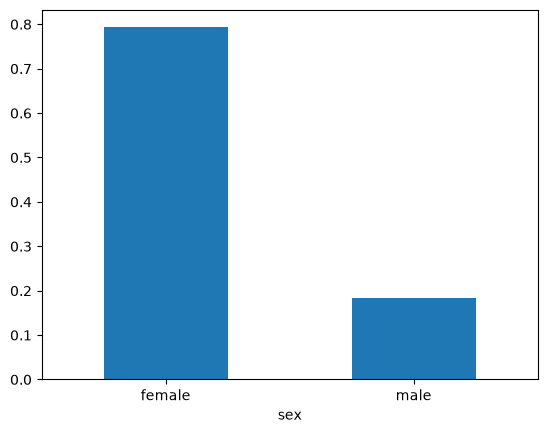

In [57]:
titanic_vc_adult = titanic_vc.query("age_group=='adult'")

(
    titanic_vc_adult.groupby('sex')['s_rate']
        .mean()
        .plot.bar(rot=0)
)

### Task 2 

Compare the mean survival rates of adults by class.

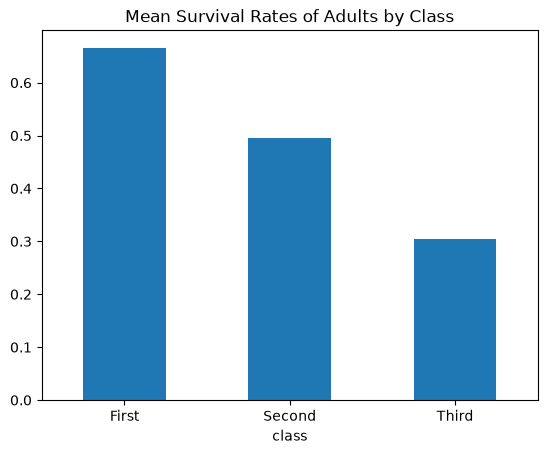

In [58]:
( titanic_vc_adult.groupby('class')['s_rate']
  .mean()
  .plot.bar(rot=0,title="Mean Survival Rates of Adults by Class")
)

plt.show()

### Task 3

Compare the mean survival rates of adults by sex and class. 

Note: The order of the categories matters. The first group should be displayed on the x axis.

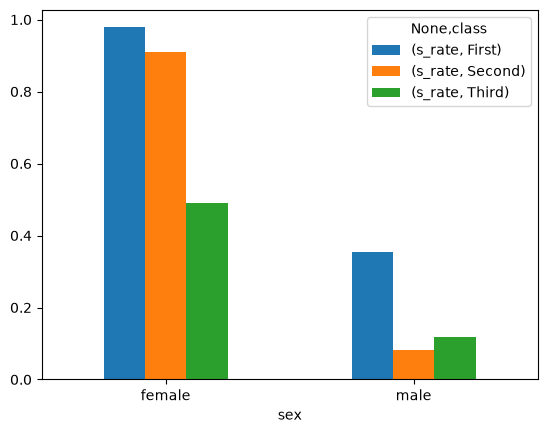

In [59]:
(
    titanic_vc_adult.unstack()
        .groupby('sex','class')['s_rate']
        .mean()
        .plot.bar(rot=0)
)

plt.show()

### Task 4

Compare the survival rates of adults by class and sex. 

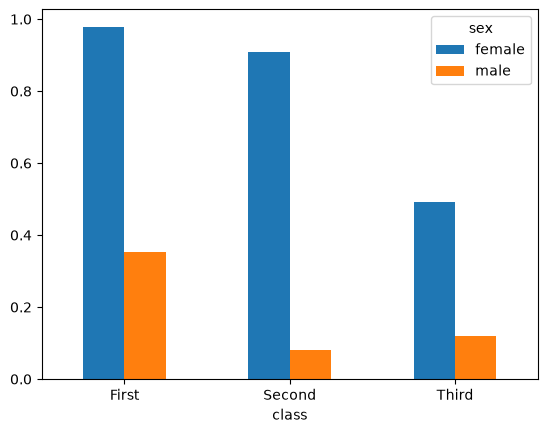

In [66]:
(
    titanic_vc_adult
        .groupby(['class','sex'])
        .s_rate.mean()
        .unstack()
        .plot.bar(rot=0)

)

plt.show()


### Task 5


Based on the preceding plots, who had a greater survival rate?

- First class males
- Third class females

In [ ]:
#third class females

**Answer:** 